In [8]:
import tensorflow as tf
import sklearn
from tensorflow.keras.datasets import mnist
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torchvision import datasets, transforms

In [9]:
transform = transforms.ToTensor()

In [2]:
(x_train, y_train), (x_test, y_test) = mnist.load_data()

2


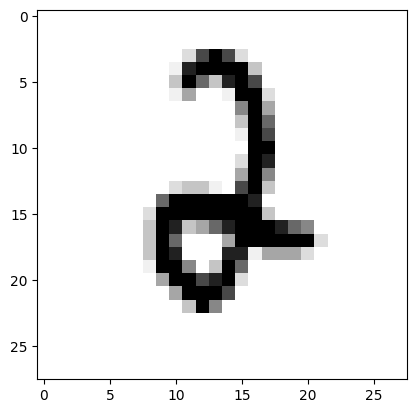

In [3]:
import matplotlib.pyplot as plt

image_index=3642
print(y_train[image_index])
plt.imshow(x_train[image_index], cmap="Greys")
plt.show()

In [4]:
x_train = x_train.reshape(x_train.shape[0], 28, 28, 1)
x_test = x_test.reshape(x_test.shape[0], 28, 28, 1)
x_train = x_train.astype('float32')
x_test = x_test.astype('float32')
# Normalizing the RGB codes by dividing it to the max RGB value.
x_train /= 255
x_test /= 255
print('x_train shape:', x_train.shape)
print('Number of images in x_train', x_train.shape[0])
print('Number of images in x_test', x_test.shape[0])

x_train shape: (60000, 28, 28, 1)
Number of images in x_train 60000
Number of images in x_test 10000


In [ ]:
# writing mobel config
class LeMet5(nn.Module):
    def __init__(self):
        super(LeNet5, self).__init__()
        self.conv1 = nn.Conv2d(
            in_channels=1,
            out_channels=6,
            kernel_size=5,
            padding=2
        )
        self.pool = nn.MaxPool2d(2,2)
        self.conv2 = nn.Conv2d(
            in_channels=1,
            out_channels=16,
            kernel_size=5
        )
        self.fc1 = nn.Linear(16*5*5, 120)
        self.fc2 = nn.Linear(120, 100)
        self.fc3 = nn.Linear(100, 10)

    def forward(self, x):
        x = self.conv1(x)        # Conv1: 6 feature maps
        x = F.relu(x)
        x = self.pool(x)         # Pooling: 2x2
        x = self.conv2(x)        # Conv2: 16 feature maps
        x = F.relu(x)
        x = self.pool(x)         # Pooling: 2x2
        x = x.view(-1, 16*5*5)   # Flatten
        x = F.relu(self.fc1(x))  # FC1: 120 neurons
        x = F.relu(self.fc2(x))  # FC2: 100 neurons
        x = F.softmax(self.fc3(x), dim=1)  # Output: 10 classes (softmax)
        return x
